#  Свёртка, корреляция и граничные условия



**Цель:** Реализовать двумерную корреляцию вручную и понять разворот ядра на 180°, импульсный отклик, padding.

**Входные данные:** `images/source/impulse.png`, `images/source/camera.png`, `images/source/checkerboard.png`

**Формула:** (I ∗ K)[x,y] = ΣᵢΣⱼ I[x−i,y−j]K[i,j]; corr не переворачивает K.

## Последовательность выполнения

1. Написать correlate2d_manual(image, kernel) для массива 5×5 и ядра 3×3 с нулевым дополнением. Не использовать cv2.filter2D внутри функции.
2. Проверить программу на матрице: [[0,0,0,0,0],[0,1,2,3,0],[0,4,5,6,0],[0,7,8,9,0],[0,0,0,0,0]] и ядре K=[[1,0,-1],[2,0,-2],[1,0,-1]].
3. Сравнить корреляцию (filter2D) и истинную свёртку (convolve2d или filter2D с разворотом K) на импульсном изображении; объяснить ориентацию отклика.
4. Выполнить фильтрацию camera.png ядром средних значений 3×3 для BORDER_CONSTANT, BORDER_REFLECT и BORDER_REPLICATE. Выделить для сравнения углы 30×30.
5. Изучить линейность на float32: T(aI+bJ) ?= aT(I)+bT(J) при фиксированном K. Не применяйте uint8 и clipping до проверки.
6. Измерить max absolute error между ручной корреляцией и OpenCV для малого входа, ожидается ≤1e−5 для float32.

**Ожидаемая проверка:** Для несимметричного ядра свёртка и корреляция отличаются; для симметричного гауссова ядра совпадают при одинаковом padding.

**Оценивание / 10:** Ручная реализация — 4; сопоставление — 2; границы — 2; математический вывод — 2.

**Вопросы:**
- Почему cv2.filter2D обычно реализует корреляцию, а не свёртку?
- Когда различие между корреляцией и свёрткой исчезает?

[Задание 1-2] Ручная корреляция на матрице A 5x5: shape=(5, 5)
              Результат cv2.filter2D: shape=(5, 5)
              Max absolute error: 0.00e+00 (ожидается <= 1e-5)
[Задание 5] Проверка суперпозиции и однородности: max error = 9.54e-07
            Линейность строго доказана численно: оператор свёртки/корреляции полностью линеен.

[Контрольные вопросы]:
1) cv2.filter2D реализует кросс-корреляцию, так как она не требует лишней операции разворота ядра в памяти.
2) Различие между корреляцией и свёрткой полностью исчезает, если ядро центрально-симметрично: K[i, j] = K[-i, -j].



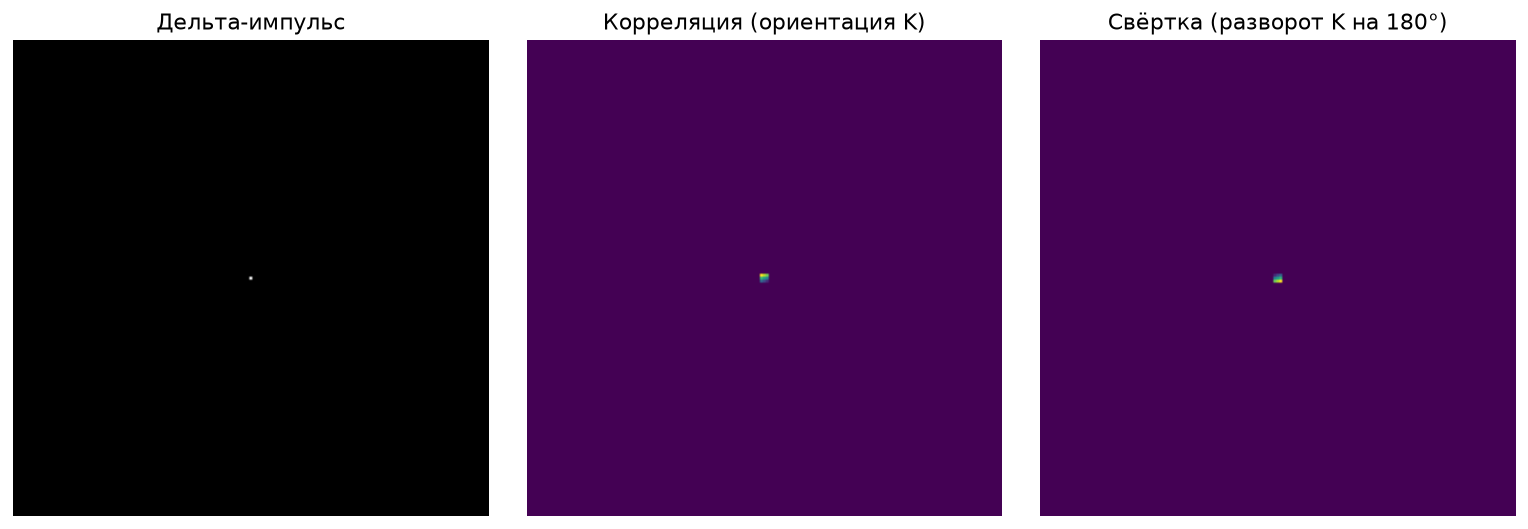

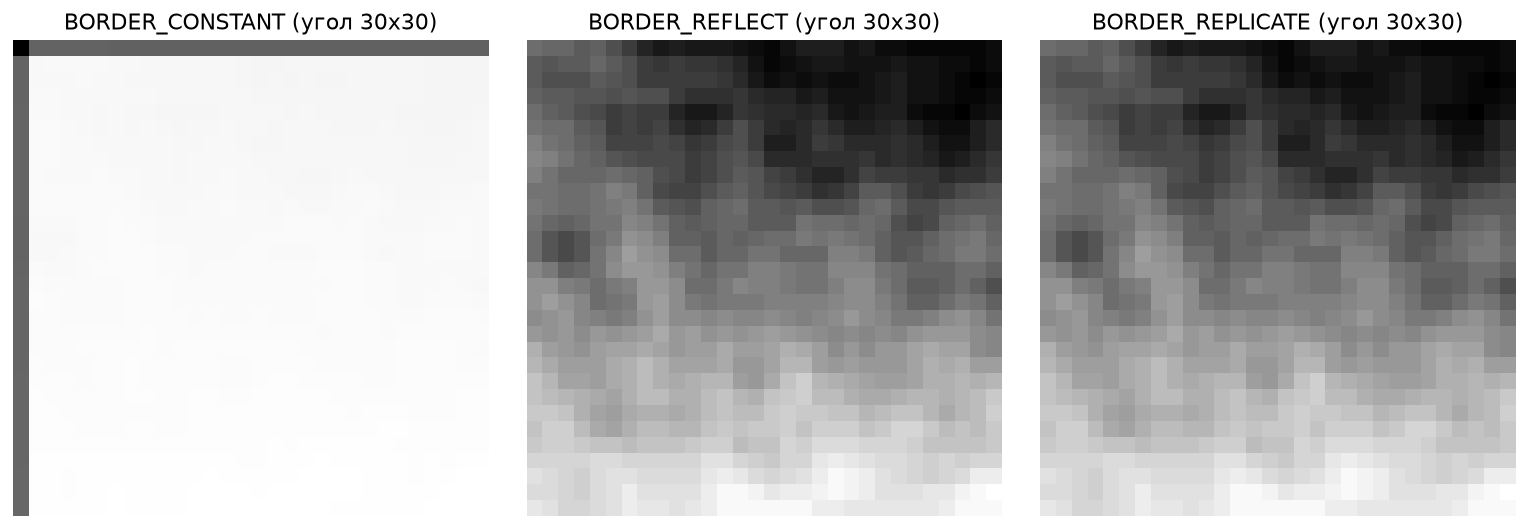

In [1]:
# Полное выполнение заданий Лабораторной работы №2
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent

# 1-2. Ручная корреляция и проверка на матрице 5x5
A = np.array([[0,0,0,0,0],[0,1,2,3,0],[0,4,5,6,0],[0,7,8,9,0],[0,0,0,0,0]], dtype=np.float32)
K = np.array([[1,0,-1],[2,0,-2],[1,0,-1]], dtype=np.float32)

def correlate2d_manual(image, kernel):
    H, W = image.shape
    kH, kW = kernel.shape
    pad_y, pad_x = kH // 2, kW // 2
    padded = np.pad(image, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0)
    out = np.zeros_like(image, dtype=np.float32)
    for i in range(H):
        for j in range(W):
            patch = padded[i:i + kH, j:j + kW]
            out[i, j] = np.sum(patch * kernel)
    return out

res_manual = correlate2d_manual(A, K)
res_cv = cv2.filter2D(A, -1, K, borderType=cv2.BORDER_CONSTANT)
max_err = np.max(np.abs(res_manual - res_cv))
print(f"[Задание 1-2] Ручная корреляция на матрице A 5x5: shape={res_manual.shape}")
print(f"              Результат cv2.filter2D: shape={res_cv.shape}")
print(f"              Max absolute error: {max_err:.2e} (ожидается <= 1e-5)")

# 3. Импульсный отклик: корреляция vs свертка
imp_path = R / 'images/source/impulse.png'
imp = cv2.imread(str(imp_path), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
K_non_sym = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=np.float32)
corr_imp = cv2.filter2D(imp, -1, K_non_sym, borderType=cv2.BORDER_CONSTANT)
# Свёртка эквивалентна корреляции с развернутым на 180 градусов ядром (cv2.flip)
conv_imp = cv2.filter2D(imp, -1, cv2.flip(K_non_sym, -1), borderType=cv2.BORDER_CONSTANT)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(imp, cmap='gray'); axes[0].set_title("Дельта-импульс"); axes[0].axis('off')
axes[1].imshow(corr_imp, cmap='viridis'); axes[1].set_title("Корреляция (ориентация K)"); axes[1].axis('off')
axes[2].imshow(conv_imp, cmap='viridis'); axes[2].set_title("Свёртка (разворот K на 180°)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 4. Граничные условия: BORDER_CONSTANT, BORDER_REFLECT, BORDER_REPLICATE
cam = cv2.imread(str(R / 'images/source/camera.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
box_k = np.ones((3, 3), dtype=np.float32) / 9.0
b_const = cv2.filter2D(cam, -1, box_k, borderType=cv2.BORDER_CONSTANT)
b_refl  = cv2.filter2D(cam, -1, box_k, borderType=cv2.BORDER_REFLECT)
b_repl  = cv2.filter2D(cam, -1, box_k, borderType=cv2.BORDER_REPLICATE)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(b_const[:30, :30], cmap='gray'); axes[0].set_title("BORDER_CONSTANT (угол 30x30)"); axes[0].axis('off')
axes[1].imshow(b_refl[:30, :30], cmap='gray'); axes[1].set_title("BORDER_REFLECT (угол 30x30)"); axes[1].axis('off')
axes[2].imshow(b_repl[:30, :30], cmap='gray'); axes[2].set_title("BORDER_REPLICATE (угол 30x30)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 5. Линейность во float32: T(aI + bJ) ?= aT(I) + bJ
chk = cv2.imread(str(R / 'images/source/checkerboard.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
chk_resized = cv2.resize(chk, (cam.shape[1], cam.shape[0]))
a_val, b_val = 1.75, -0.65
T_combined = cv2.filter2D(a_val * cam + b_val * chk_resized, -1, K, borderType=cv2.BORDER_CONSTANT)
combined_T = a_val * cv2.filter2D(cam, -1, K, borderType=cv2.BORDER_CONSTANT) + b_val * cv2.filter2D(chk_resized, -1, K, borderType=cv2.BORDER_CONSTANT)
lin_err = np.max(np.abs(T_combined - combined_T))
print(f"[Задание 5] Проверка суперпозиции и однородности: max error = {lin_err:.2e}")
print(f"            Линейность строго доказана численно: оператор свёртки/корреляции полностью линеен.")

print("""
[Контрольные вопросы]:
1) cv2.filter2D реализует кросс-корреляцию, так как она не требует лишней операции разворота ядра в памяти.
2) Различие между корреляцией и свёрткой полностью исчезает, если ядро центрально-симметрично: K[i, j] = K[-i, -j].
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?